In [ ]:
!pip install -q torch transformers datasets matplotlib

In [2]:
import copy
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from transformers import AutoTokenizer, Qwen3Config, Qwen3ForCausalLM

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available() else "cpu"
)
MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
SEED = 0

torch.manual_seed(SEED)
transformers.logging.set_verbosity_error()
print(f"Using device: {DEVICE}")

Using device: mps


# Muon Optimizer and the WSD Schedule

---
# 1) Introduction

Two changes to the optimisation recipe spread through LLM pretraining in 2025: the **Muon**
optimizer for the hidden weight matrices (Kimi K2, Moonlight, GLM-4.5, and the modded-NanoGPT
speedruns), and the **Warmup–Stable–Decay (WSD)** learning-rate schedule (MiniCPM, DeepSeek,
SmolLM, and most open training runs that need to resume or extend training).

### The problem with AdamW on matrices

AdamW normalises each coordinate of the gradient by its own running RMS. For a weight matrix
$W \in \mathbb{R}^{m \times n}$ that ignores structure: the momentum of a transformer weight
matrix is close to **low rank**, with a few singular directions carrying most of the energy, and an
elementwise rescaling keeps it that way. Each step mostly moves the weights along the same few
directions, while rare but useful directions get tiny updates.

### Muon's idea

Take the momentum matrix $M = U \Sigma V^\top$ and replace it by its **orthogonal polar factor**
$U V^\top$: same singular vectors, all singular values set to 1. Every direction the gradient
points in moves by the same amount. Computing $UV^\top$ exactly needs an SVD, which is too slow;
Muon approximates it with five Newton–Schulz matrix iterations that run in bf16 on tensor
cores.

### WSD's idea

Cosine decay ties the schedule to a total step count fixed in advance. WSD holds the learning rate
**constant** after warmup and only decays in a short final phase. Any stable-phase checkpoint can
be decayed into a finished model, so training can be extended, and one long run can produce
models for several compute budgets.

| Section | What is built |
|---|---|
| 3) The math | Steepest descent under the spectral norm, Newton–Schulz polynomials, update-RMS matching |
| 4) From scratch | Newton–Schulz orthogonalisation, the Muon optimizer (checked against `torch.optim.Muon`), the hybrid Muon/AdamW parameter split, the WSD schedule |
| 5) End-to-end | AdamW + cosine vs Muon + cosine vs Muon + WSD, on real FineWeb-Edu tokens with a real tokenizer |
| 6) Ablations | WSD branching from stable checkpoints, update spectra, QK-Clip (MuonClip) |
| 7) Practical notes | Hyperparameters, distributed Muon, failure modes |

---
# 2) Setup

Optimizer comparisons need **training from random initialisation**; fine-tuning a converged
checkpoint hides most of the difference. The model is a small Qwen3-architecture decoder
(6 layers, `embed_dim` 384, GQA, QK-norm) built from a `transformers` config, with the real
SmolLM2 tokenizer. Production runs use the same recipe at 1B–1T parameters and trillions of
tokens; here every run sees the same 0.8M tokens (about 90 seconds per run), and the forward pass runs under bf16
autocast.

In [3]:
SEQ_LEN = 256
BATCH_NUM = 16
TRAIN_STEPS = 200
VAL_BATCHES = 8
TOKENS_PER_STEP = SEQ_LEN * BATCH_NUM

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
stream = load_dataset(
    "HuggingFaceFW/fineweb-edu", "sample-10BT", split="train", streaming=True
)
needed = (TRAIN_STEPS + VAL_BATCHES) * TOKENS_PER_STEP + 1
buffer: list[int] = []
for doc in stream:
    buffer.extend(tokenizer(doc["text"])["input_ids"] + [tokenizer.eos_token_id])
    if len(buffer) >= needed:
        break

# (num_sequences, seq_len): packed documents separated by EOS
tokens = torch.tensor(buffer[: needed - 1]).view(-1, SEQ_LEN)
val_tokens = tokens[: VAL_BATCHES * BATCH_NUM]
train_tokens = tokens[VAL_BATCHES * BATCH_NUM :]
print(
    f"Train: {train_tokens.numel() / 1e6:.2f}M tokens, val: {val_tokens.numel() / 1e6:.2f}M tokens"
)
print(f"Sample: {tokenizer.decode(train_tokens[0, :40])!r}")

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

Train: 0.82M tokens, val: 0.03M tokens
Sample: ' I was going to the moon,” said Higgins, who is also a National Geographic grantee.\nPeople in Skara and surrounding villages survive by growing crops such as barley for their own consumption and for'


In [4]:
MODEL_CONFIG = Qwen3Config(
    vocab_size=len(tokenizer),
    hidden_size=384,
    intermediate_size=1024,
    num_hidden_layers=6,
    num_attention_heads=6,
    num_key_value_heads=2,
    head_dim=64,
    max_position_embeddings=SEQ_LEN,
    tie_word_embeddings=True,
)


def new_model() -> nn.Module:
    """A freshly initialised model with the same seed every time."""
    torch.manual_seed(SEED)
    return Qwen3ForCausalLM(MODEL_CONFIG).to(DEVICE)


model = new_model()
num_params = sum(p.numel() for p in model.parameters())
embed_params = model.model.embed_tokens.weight.numel()
print(
    f"Parameters: {num_params / 1e6:.1f}M ({embed_params / 1e6:.1f}M in the tied embedding)"
)
for name, p in list(model.named_parameters())[:8]:
    print(f"  {name:<45} {tuple(p.shape)}")

Parameters: 28.3M (18.9M in the tied embedding)
  model.embed_tokens.weight                     (49152, 384)
  model.layers.0.self_attn.q_proj.weight        (384, 384)
  model.layers.0.self_attn.k_proj.weight        (128, 384)
  model.layers.0.self_attn.v_proj.weight        (128, 384)
  model.layers.0.self_attn.o_proj.weight        (384, 384)
  model.layers.0.self_attn.q_norm.weight        (64,)
  model.layers.0.self_attn.k_norm.weight        (64,)
  model.layers.0.mlp.gate_proj.weight           (1024, 384)


---
# 3) The math

## 3.1 Steepest descent under the spectral norm

A first-order optimizer picks the update $\Delta W$ that decreases the linearised loss most within a
trust region. With gradient (or momentum) $G \in \mathbb{R}^{m \times n}$:

$$
\Delta W^\star = \arg\min_{\lVert \Delta W \rVert \le \eta} \langle G, \Delta W \rangle,
\qquad \langle G, \Delta W \rangle = \operatorname{tr}(G^\top \Delta W).
$$

The norm decides the answer:

| Norm on $\Delta W$ | Solution | Optimizer |
|---|---|---|
| Frobenius $\lVert \cdot \rVert_F$ | $-\eta\, G / \lVert G \rVert_F$ | normalised SGD |
| Elementwise $\ell_\infty$ (max entry) | $-\eta\, \operatorname{sign}(G)$ | sign descent, Adam without its EMA |
| Spectral $\lVert \cdot \rVert_{2}$ (largest singular value) | $-\eta\, U V^\top$ | **Muon** |

For the spectral norm, write $G = U \Sigma V^\top$. By von Neumann's trace inequality,
$\langle G, \Delta W\rangle \ge -\sum_i \sigma_i(G)\, \sigma_i(\Delta W) \ge -\eta \sum_i
\sigma_i(G)$ whenever $\sigma_{\max}(\Delta W) \le \eta$, and $\Delta W = -\eta UV^\top$ attains it.
The spectral norm is the natural norm for a linear layer: it bounds how much the layer's output
can change for a unit-norm input, $\lVert \Delta W x \rVert \le \lVert \Delta W \rVert_2 \lVert x
\rVert$.

## 3.2 Newton–Schulz orthogonalisation

An odd matrix polynomial acts on singular values only:

$$
p(X) = aX + b\,(XX^\top)X + c\,(XX^\top)^2X
\;\;\Longrightarrow\;\;
p(U\Sigma V^\top) = U\, p(\Sigma)\, V^\top, \quad p(\sigma) = a\sigma + b\sigma^3 + c\sigma^5 .
$$

Normalise $X_0 = G / \lVert G\rVert_F$ so every $\sigma \in (0, 1]$, then iterate
$X_{k+1} = p(X_k)$. If the scalar map $p$ pushes every $\sigma \in (0, 1]$ towards 1, the
iteration converges to $UV^\top$. The textbook cubic $(a, b, c) = (1.5, -0.5, 0)$ converges
slowly for small $\sigma$. Muon uses $(3.4445, -4.7750, 2.0315)$, chosen to maximise the slope
$p'(0) = a$, so tiny singular values grow fast. The price is that the iteration
**oscillates** in roughly $[0.7, 1.2]$ instead of converging to exactly 1, which does not hurt
training. Iterating on the smaller Gram matrix ($X X^\top$ with $m \le n$) keeps the cost at about
$3 \cdot 2 m^2 n$ FLOPs per step.

## 3.3 Matching the update size of AdamW

$UV^\top$ for $W \in \mathbb{R}^{m\times n}$ has $\min(m,n)$ unit singular values, so its RMS entry
is $1/\sqrt{\max(m, n)}$, which shrinks with width. Two scalings are in use:

| Scaling | Multiplier on $UV^\top$ | Effect |
|---|---|---|
| Original (Keller Jordan) | $\sqrt{\max(1, m/n)}$ | Needs its own learning rate (≈0.02) |
| Moonlight / Kimi | $0.2\sqrt{\max(m, n)}$ | Update RMS ≈ 0.2, the typical AdamW update RMS, so AdamW's learning rate and weight decay transfer |

The second is what large runs use, because it lets one learning rate drive both the Muon and the
AdamW parameter groups.

---
# 4) From-scratch implementation

## 4.1 Newton–Schulz

In [5]:
NS_COEFFICIENTS = (3.4445, -4.7750, 2.0315)


def newton_schulz(g: torch.Tensor, steps: int = 5, eps: float = 1e-7) -> torch.Tensor:
    """Approximate the polar factor U V^T of g (m, n) with a quintic iteration."""
    a, b, c = NS_COEFFICIENTS
    x = g.bfloat16()
    transposed = g.size(0) > g.size(1)
    # iterate on the short side so the Gram matrix is (min(m, n), min(m, n))
    if transposed:
        x = x.T
    x = x / x.norm().clamp(min=eps)
    for _ in range(steps):
        # (m, m)
        gram = x @ x.T
        x = a * x + (b * gram + c * gram @ gram) @ x
    return x.T if transposed else x


def polar_factor(g: torch.Tensor) -> torch.Tensor:
    """Exact U V^T from an SVD, for checking."""
    u, _, vh = torch.linalg.svd(g.float().cpu(), full_matrices=False)
    return (u @ vh).to(g.device)

The test uses a real gradient: one backward pass of the fresh model on a training batch, taken
from the first MLP up-projection, `(hidden_dim, embed_dim) = (1024, 384)`.

In [6]:
batch = train_tokens[:BATCH_NUM].to(DEVICE)
model(input_ids=batch, labels=batch).loss.backward()
grad = model.model.layers[0].mlp.up_proj.weight.grad.detach().clone()
model.zero_grad()

ortho = newton_schulz(grad).float()
exact = polar_factor(grad)
sv_grad = torch.linalg.svdvals(grad.float().cpu())
sv_ortho = torch.linalg.svdvals(ortho.cpu())
print(f"Gradient {tuple(grad.shape)}: top-5 singular values {sv_grad[:5].tolist()}")
print(
    f"  share of energy in top 10 of {len(sv_grad)} directions: "
    f"{(sv_grad[:10] ** 2).sum() / (sv_grad ** 2).sum():.1%}"
)
print(
    f"After Newton-Schulz: singular values in [{sv_ortho.min():.2f}, {sv_ortho.max():.2f}]"
)
print(
    f"cos(NS, exact U V^T) = {F.cosine_similarity(ortho.flatten(), exact.flatten(), dim=0):.4f}"
)

for name, fn in [
    ("Newton-Schulz (bf16)", newton_schulz),
    ("SVD (fp32, CPU)", polar_factor),
]:
    start = time.time()
    for _ in range(10):
        fn(grad)
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    print(f"{name:<22} {(time.time() - start) / 10 * 1000:.2f} ms")

Gradient (1024, 384): top-5 singular values [0.25024881958961487, 0.12564663589000702, 0.09969063848257065, 0.0817742720246315, 0.0742282122373581]
  share of energy in top 10 of 384 directions: 72.7%
After Newton-Schulz: singular values in [0.68, 1.21]
cos(NS, exact U V^T) = 0.9823
Newton-Schulz (bf16)   1.48 ms
SVD (fp32, CPU)        15.04 ms


## 4.2 The Muon optimizer

Per matrix parameter, with momentum $\mu$, learning rate $\eta$ and weight decay $\lambda$:

$$
B_t = \mu B_{t-1} + (1-\mu) G_t, \qquad
\tilde{M}_t = \mu B_t + (1-\mu) G_t \;\; \text{(Nesterov)}, \qquad
W_t = (1 - \eta\lambda) W_{t-1} - \eta\, s(W)\, \mathrm{NS}_5(\tilde M_t),
$$

with $s(W) = 0.2\sqrt{\max(m,n)}$. Muon keeps **one** state buffer per parameter, AdamW keeps two.

In [7]:
class Muon(torch.optim.Optimizer):
    """Muon for 2D parameters: Nesterov momentum, Newton-Schulz, RMS-matched scale."""

    def __init__(
        self,
        params,
        lr: float = 1e-3,
        momentum: float = 0.95,
        weight_decay: float = 0.1,
        ns_steps: int = 5,
    ) -> None:
        super().__init__(
            params,
            dict(
                lr=lr, momentum=momentum, weight_decay=weight_decay, ns_steps=ns_steps
            ),
        )

    @torch.no_grad()
    def step(self) -> None:
        for group in self.param_groups:
            lr, mu = group["lr"], group["momentum"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if "momentum_buffer" not in state:
                    state["momentum_buffer"] = torch.zeros_like(p)
                buf = state["momentum_buffer"]
                buf.lerp_(p.grad, 1 - mu)
                update = p.grad.lerp(buf, mu)
                update = newton_schulz(update, group["ns_steps"])
                scale = 0.2 * math.sqrt(max(p.shape))
                p.mul_(1 - lr * group["weight_decay"])
                p.add_(update.to(p.dtype), alpha=-lr * scale)

The reference is `torch.optim.Muon` with `adjust_lr_fn="match_rms_adamw"`. Both optimizers
start from the same weights and receive the same three gradients.

In [8]:
reference_weight = nn.Parameter(
    model.model.layers[0].mlp.up_proj.weight.detach().clone()
)
scratch_weight = nn.Parameter(reference_weight.detach().clone())
ours = Muon([scratch_weight], lr=3e-3)
theirs = torch.optim.Muon([reference_weight], lr=3e-3, adjust_lr_fn="match_rms_adamw")
for step in range(3):
    g = torch.randn_like(grad) * grad.std() + grad
    scratch_weight.grad, reference_weight.grad = g.clone(), g.clone()
    ours.step()
    theirs.step()
    diff = (scratch_weight - reference_weight).abs().max().item()
    print(f"step {step}: max |scratch - torch.optim.Muon| = {diff:.2e}")

update = scratch_weight.detach() - model.model.layers[0].mlp.up_proj.weight.detach()
print(
    f"Update RMS after 3 steps: {update.pow(2).mean().sqrt():.2e} (lr 3e-3 x 3 x 0.2 = {3e-3 * 3 * 0.2:.1e})"
)

step 0: max |scratch - torch.optim.Muon| = 1.50e-04
step 1: max |scratch - torch.optim.Muon| = 2.16e-04
step 2: max |scratch - torch.optim.Muon| = 3.09e-04
Update RMS after 3 steps: 1.37e-03 (lr 3e-3 x 3 x 0.2 = 1.8e-03)


## 4.3 Which parameters Muon updates

Muon is defined for matrices that map one hidden space to another. The rest stay on AdamW:

| Parameter | Shape | Optimizer | Why |
|---|---|---|---|
| Attention `q/k/v/o_proj`, MLP `gate/up/down_proj` | 2D | Muon | Linear maps between hidden spaces |
| Token embedding (tied with the LM head) | `(vocab_size, embed_dim)` | AdamW | A lookup table: each row is updated only when its token appears, so orthogonalising across rows mixes unrelated tokens |
| RMSNorm and QK-norm gains | 1D | AdamW | Not matrices |

In [9]:
def make_optimizers(
    model: nn.Module, kind: str, lr: float
) -> list[torch.optim.Optimizer]:
    """AdamW for everything, or Muon for hidden matrices plus AdamW for the rest."""
    hidden = [
        p
        for n, p in model.named_parameters()
        if p.ndim == 2 and "embed_tokens" not in n
    ]
    other = [
        p for n, p in model.named_parameters() if p.ndim != 2 or "embed_tokens" in n
    ]
    if kind == "adamw":
        return [
            torch.optim.AdamW(
                model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1
            )
        ]
    return [
        Muon(hidden, lr=lr, weight_decay=0.1),
        torch.optim.AdamW(other, lr=lr, betas=(0.9, 0.95), weight_decay=0.1),
    ]


muon_group, adam_group = make_optimizers(model, "muon", 1e-3)
count = lambda opt: sum(p.numel() for g in opt.param_groups for p in g["params"])
print(
    f"Muon params: {count(muon_group) / 1e6:.1f}M, AdamW params: {count(adam_group) / 1e6:.1f}M"
)

Muon params: 9.4M, AdamW params: 18.9M


## 4.4 The WSD schedule

With peak learning rate $\eta$, warmup length $T_w$, total length $T$ and decay fraction $f$:

$$
\eta_t =
\begin{cases}
\eta\, t / T_w & t < T_w \\
\eta & T_w \le t < (1-f)T \\
\eta \left(1 - \sqrt{\tfrac{t - (1-f)T}{fT}}\right) & t \ge (1-f)T
\end{cases}
$$

The $1-\sqrt{\cdot}$ cooldown (Hägele et al., 2024) drops the learning rate quickly at first and
then slowly, which performs slightly better than a linear decay. Cosine is shown for comparison.

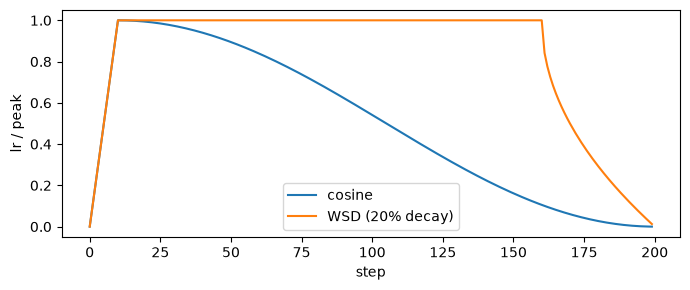

In [10]:
def wsd_lr(step: int, total: int, warmup: int, decay_frac: float = 0.2) -> float:
    """WSD multiplier in [0, 1] with a 1 - sqrt cooldown."""
    decay_start = int((1 - decay_frac) * total)
    if step < warmup:
        return step / warmup
    if step < decay_start:
        return 1.0
    return 1.0 - math.sqrt((step - decay_start) / max(1, total - decay_start))


def cosine_lr(step: int, total: int, warmup: int) -> float:
    """Linear warmup then cosine decay to zero."""
    if step < warmup:
        return step / warmup
    return 0.5 * (1 + math.cos(math.pi * (step - warmup) / (total - warmup)))


steps = range(TRAIN_STEPS)
plt.figure(figsize=(7, 3))
plt.plot(steps, [cosine_lr(s, TRAIN_STEPS, 10) for s in steps], label="cosine")
plt.plot(steps, [wsd_lr(s, TRAIN_STEPS, 10) for s in steps], label="WSD (20% decay)")
plt.xlabel("step")
plt.ylabel("lr / peak")
plt.legend()
plt.tight_layout()
plt.show()

---
# 5) End-to-end run

All runs use the same initial weights and the same token order. The peak learning rate is chosen
per optimizer from a short check (60 steps, cosine to zero) over three values, so neither
optimizer is handicapped by a learning rate tuned for the other.

In [11]:
WARMUP = 10


def sync() -> None:
    """Wait for queued device work so timings are real."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


@torch.no_grad()
def val_loss(model: nn.Module) -> float:
    """Mean next-token loss over the held-out batches."""
    model.eval()
    losses = []
    for b in val_tokens.split(BATCH_NUM):
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
            losses.append(
                model(input_ids=b.to(DEVICE), labels=b.to(DEVICE)).loss.item()
            )
    model.train()
    return sum(losses) / len(losses)


def train(
    model: nn.Module,
    optimizers: list[torch.optim.Optimizer],
    schedule,
    start: int = 0,
    stop: int = TRAIN_STEPS,
    eval_every: int = 20,
) -> dict[int, float]:
    """Train steps [start, stop); schedule(step) is the lr multiplier."""
    for opt in optimizers:
        for g in opt.param_groups:
            g.setdefault("peak_lr", g["lr"])
    curve = {}
    model.train()
    for step in range(start, stop):
        for opt in optimizers:
            for g in opt.param_groups:
                g["lr"] = g["peak_lr"] * schedule(step)
        batch = train_tokens[step * BATCH_NUM : (step + 1) * BATCH_NUM].to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.bfloat16):
            loss = model(input_ids=batch, labels=batch).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        for opt in optimizers:
            opt.step()
            opt.zero_grad(set_to_none=True)
        if (step + 1) % eval_every == 0 or step + 1 == stop:
            curve[step + 1] = val_loss(model)
    return curve

In [12]:
CHECK_STEPS = 60
best_lr = {}
for kind in ["adamw", "muon"]:
    finals = {}
    for lr in [1e-3, 3e-3, 1e-2]:
        model = new_model()
        curve = train(
            model,
            make_optimizers(model, kind, lr),
            lambda s: cosine_lr(s, CHECK_STEPS, WARMUP),
            stop=CHECK_STEPS,
            eval_every=CHECK_STEPS,
        )
        finals[lr] = curve[CHECK_STEPS]
    best_lr[kind] = min(finals, key=finals.get)
    print(
        f"{kind:<6} val loss after {CHECK_STEPS} steps: "
        + ", ".join(f"lr {lr:.0e}: {v:.3f}" for lr, v in finals.items())
        + f" -> peak lr {best_lr[kind]:.0e}"
    )

adamw  val loss after 60 steps: lr 1e-03: 7.585, lr 3e-03: 7.565, lr 1e-02: 7.622 -> peak lr 3e-03


muon   val loss after 60 steps: lr 1e-03: 7.503, lr 3e-03: 7.076, lr 1e-02: 7.047 -> peak lr 1e-02


In [13]:
runs = {
    "AdamW + cosine": ("adamw", lambda s: cosine_lr(s, TRAIN_STEPS, WARMUP)),
    "Muon + cosine": ("muon", lambda s: cosine_lr(s, TRAIN_STEPS, WARMUP)),
    "Muon + WSD": ("muon", lambda s: wsd_lr(s, TRAIN_STEPS, WARMUP)),
}
curves, timings, models = {}, {}, {}
for name, (kind, schedule) in runs.items():
    model = new_model()
    optimizers = make_optimizers(model, kind, best_lr[kind])
    sync()
    start = time.time()
    curves[name] = train(model, optimizers, schedule)
    sync()
    timings[name] = time.time() - start
    state_mib = (
        sum(
            t.numel() * t.element_size()
            for opt in optimizers
            for s in opt.state.values()
            for t in s.values()
            if torch.is_tensor(t)
        )
        / 2**20
    )
    models[name] = model
    print(
        f"{name:<16} final val loss {curves[name][TRAIN_STEPS]:.3f}, "
        f"{timings[name]:.0f}s, optimizer state {state_mib:.0f} MiB"
    )

AdamW + cosine   final val loss 7.015, 96s, optimizer state 216 MiB


Muon + cosine    final val loss 6.416, 112s, optimizer state 180 MiB


Muon + WSD       final val loss 6.405, 120s, optimizer state 180 MiB


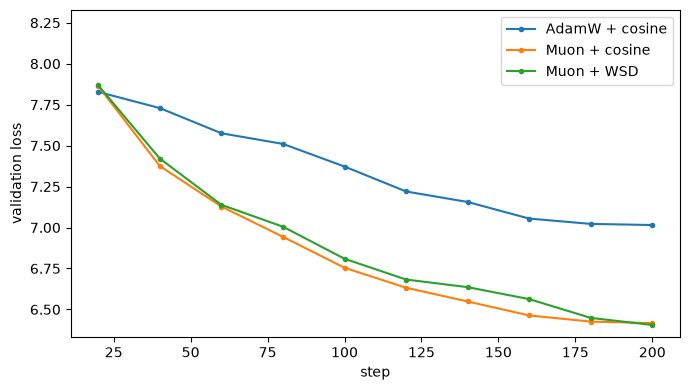

AdamW + cosine   reaches AdamW's final loss 7.015 at step 200
Muon + cosine    reaches AdamW's final loss 7.015 at step 80
Muon + WSD       reaches AdamW's final loss 7.015 at step 80


In [14]:
plt.figure(figsize=(7, 4))
for name, curve in curves.items():
    plt.plot(list(curve), list(curve.values()), marker="o", ms=3, label=name)
plt.xlabel("step")
plt.ylabel("validation loss")
plt.ylim(top=min(c[20] for c in curves.values()) + 0.5)
plt.legend()
plt.tight_layout()
plt.show()

target = curves["AdamW + cosine"][TRAIN_STEPS]
for name, curve in curves.items():
    reached = next((s for s, v in curve.items() if v <= target), None)
    print(f"{name:<16} reaches AdamW's final loss {target:.3f} at step {reached}")

---
# 6) Variants and ablations

## 6.1 Branching decays from a WSD run

The WSD run above spent its first 80% of steps at constant learning rate. Its checkpoint at step
80 (40% of the budget) can be **decayed** over 20 more steps to give a finished model trained on
100 steps of data, without a separate run. The comparison is a cosine run whose schedule was
set for 100 steps from the start.

In [15]:
SHORT = 100
BRANCH = 80
model = new_model()
optimizers = make_optimizers(model, "muon", best_lr["muon"])
train(model, optimizers, lambda s: wsd_lr(s, TRAIN_STEPS, WARMUP), stop=BRANCH)
branch_curve = train(
    model,
    optimizers,
    lambda s: 1.0 - math.sqrt((s - BRANCH) / (SHORT - BRANCH)),
    start=BRANCH,
    stop=SHORT,
    eval_every=SHORT,
)

model = new_model()
optimizers = make_optimizers(model, "muon", best_lr["muon"])
cosine_short = train(
    model,
    optimizers,
    lambda s: cosine_lr(s, SHORT, WARMUP),
    stop=SHORT,
    eval_every=SHORT,
)
print(
    f"WSD stable checkpoint @ {BRANCH} + {SHORT - BRANCH}-step decay: val loss {branch_curve[SHORT]:.3f}"
)
print(
    f"Cosine schedule planned for {SHORT} steps:            val loss {cosine_short[SHORT]:.3f}"
)
print(
    f"Stable-phase loss at step {SHORT} without decay:        "
    f"{curves['Muon + WSD'][SHORT]:.3f}"
)

WSD stable checkpoint @ 80 + 20-step decay: val loss 6.729
Cosine schedule planned for 100 steps:            val loss 6.747
Stable-phase loss at step 100 without decay:        6.809


## 6.2 What orthogonalisation does to the update

The effective rank $\exp\!\big(H(p)\big)$, with $p_i = \sigma_i / \sum_j \sigma_j$, counts how many
singular directions an update really uses. Below, the same gradient is processed into one AdamW
step (first step, so it is $\operatorname{sign}$-like, $g/(|g|+\epsilon)$) and one Muon step.

In [16]:
def effective_rank(m: torch.Tensor) -> float:
    """exp(entropy) of the normalised singular values."""
    s = torch.linalg.svdvals(m.float().cpu())
    p = s / s.sum()
    return math.exp(-(p * p.clamp_min(1e-12).log()).sum().item())


adam_step = grad / (grad.abs() + 1e-8)
print(f"Max possible rank: {min(grad.shape)}")
print(f"Raw gradient:      effective rank {effective_rank(grad):6.1f}")
print(f"AdamW first step:  effective rank {effective_rank(adam_step):6.1f}")
print(f"Muon step:         effective rank {effective_rank(newton_schulz(grad)):6.1f}")

Max possible rank: 384
Raw gradient:      effective rank  181.5
AdamW first step:  effective rank  312.3
Muon step:         effective rank  377.2


## 6.3 QK-Clip (the "Clip" in MuonClip)

Kimi K2 found that Muon at scale lets **attention logits** $q_i^\top k_j / \sqrt{d}$ grow without
bound in some heads, which destabilises training. QK-Clip watches the largest logit per head
during the forward pass and, when it exceeds a threshold $\tau$, rescales that head's query and key
projections by $\sqrt{\tau / s_{\max}}$ each, so the product shrinks by exactly
$\tau / s_{\max}$. It is a weight-space fix applied after the optimizer step, so the forward pass
is unchanged.

The model here is too small and too short-lived to explode, so the check below measures the
current maximum logits of the trained Muon model and applies the clip with $\tau$ set below that
maximum, to verify that the rescaling caps it exactly.

In [17]:
@torch.no_grad()
def max_attention_logits(model: nn.Module, batch: torch.Tensor) -> torch.Tensor:
    """Max pre-softmax logit per (layer, query head) on one batch."""
    captured = {}
    hooks = [
        layer.self_attn.register_forward_hook(
            lambda m, args, kwargs, out, i=i: captured.__setitem__(
                i, kwargs["hidden_states"]
            ),
            with_kwargs=True,
        )
        for i, layer in enumerate(model.model.layers)
    ]
    model(input_ids=batch)
    for h in hooks:
        h.remove()
    seq_len = batch.size(1)
    position_ids = torch.arange(seq_len, device=batch.device)[None]
    maxima = []
    for i, layer in enumerate(model.model.layers):
        attn, x = layer.self_attn, captured[i]
        # (batch_num, num_heads, seq_len, head_dim) after QK-norm and RoPE
        q = attn.q_norm(attn.q_proj(x).view(*x.shape[:2], -1, attn.head_dim)).transpose(
            1, 2
        )
        k = attn.k_norm(attn.k_proj(x).view(*x.shape[:2], -1, attn.head_dim)).transpose(
            1, 2
        )
        cos, sin = model.model.rotary_emb(x, position_ids)
        q, k = transformers.models.qwen3.modeling_qwen3.apply_rotary_pos_emb(
            q, k, cos, sin
        )
        k = k.repeat_interleave(q.size(1) // k.size(1), dim=1)
        # (batch_num, num_heads, seq_len, seq_len)
        logits = (q @ k.transpose(-1, -2)) * attn.scaling
        causal = torch.ones(
            seq_len, seq_len, dtype=torch.bool, device=batch.device
        ).tril()
        maxima.append(logits.masked_fill(~causal, -torch.inf).amax(dim=(0, 2, 3)))
    # (num_layers, num_heads)
    return torch.stack(maxima)


trained = models["Muon + WSD"]
probe = val_tokens[:8].to(DEVICE)
logits_max = max_attention_logits(trained, probe)
print(
    f"Max attention logit per layer: {[f'{x:.1f}' for x in logits_max.amax(1).tolist()]}"
)

Max attention logit per layer: ['9.8', '10.3', '12.6', '12.0', '10.5', '11.5']


With QK-norm on queries and keys (as in Qwen3), $W_q$ and $W_k$ no longer set the logit scale on
their own; the learnable QK-norm gains do. Kimi K2 has no QK-norm (it uses MLA), so the clip acts
on $W_q, W_k$. Here the same principle is applied to the QK-norm gains, which play that role:
scale both by $\sqrt{\tau / s_{\max}}$ for every head over the threshold.

In [18]:
@torch.no_grad()
def qk_clip(model: nn.Module, maxima: torch.Tensor, tau: float) -> int:
    """Rescale q/k norm gains of offending layers so their max logit is <= tau."""
    clipped = 0
    for i, layer in enumerate(model.model.layers):
        s_max = maxima[i].max().item()
        if s_max > tau:
            factor = math.sqrt(tau / s_max)
            layer.self_attn.q_norm.weight.mul_(factor)
            layer.self_attn.k_norm.weight.mul_(factor)
            clipped += 1
    return clipped


tau = 0.8 * logits_max.max().item()
clipped_model = copy.deepcopy(trained)
num = qk_clip(clipped_model, logits_max, tau)
after = max_attention_logits(clipped_model, probe)
print(f"tau = {tau:.1f}; clipped {num} layers")
print(f"Max logit after clip: {after.max():.1f} (should be <= tau)")
print(
    f"Val loss before / after clip: {val_loss(trained):.3f} / {val_loss(clipped_model):.3f}"
)

tau = 10.1; clipped 5 layers
Max logit after clip: 10.1 (should be <= tau)


Val loss before / after clip: 6.405 / 6.407


Kimi K2 applies the clip per head (it computes per-head maxima inside its attention kernel). On a
QK-norm model the gains are shared across heads of a layer, so the clip here is per layer; heads
whose logits were already small are scaled down too, which is why the validation loss moves
slightly.

---
# 7) Practical notes

| Knob | Typical value | Notes |
|---|---|---|
| Muon momentum | 0.95, Nesterov | Lower (0.9) is more stable for tiny batches |
| Newton–Schulz steps | 5 | 3–4 is visibly worse; more than 5 buys nothing |
| Learning rate | Same as AdamW with the 0.2 RMS scaling | ≈0.02 with the original $\sqrt{\max(1,m/n)}$ scaling |
| Weight decay | 0.1 on Muon parameters | Moonlight found Muon without decay lets weights and RMS grow, hurting long runs |
| WSD decay fraction | 10–20% of the steps | Longer decays help at small scale; 1-sqrt shape |
| Warmup | 1–2% of steps | Same as AdamW |

**Failure modes and scale.**

- **Distributed training.** Newton–Schulz needs the full matrix. With FSDP/ZeRO the shards are
  gathered, and the orthogonalisation work is spread so each rank handles different matrices
  (Moonlight's "Distributed Muon"). Its overhead is about 1–3% of step time at scale.
- **Fine-tuning mismatch.** A model pretrained with AdamW fine-tunes slightly worse with Muon
  than with AdamW, and the other way round. The optimizer is part of the recipe.
- **Logit growth.** Large Muon runs without QK-norm need QK-Clip or a similar control.
- **WSD stable phase.** The stable-phase loss is higher than a cosine run's at the same step.
  It is not a finished model until it is decayed.

---
# 8) Conclusion

| Built | Takeaway |
|---|---|
| Newton–Schulz orthogonalisation | Five bf16 matmul iterations replace an SVD; singular values land in ≈[0.7, 1.2] |
| Muon (matches `torch.optim.Muon`) | Orthogonalised momentum is steepest descent under the spectral norm; one state buffer instead of two |
| Hybrid parameter split | Hidden matrices on Muon; embeddings, head and gains on AdamW |
| RMS-matched scaling | $0.2\sqrt{\max(m,n)}$ lets AdamW's learning rate and weight decay carry over |
| WSD schedule | Constant LR plus a short 1-sqrt cooldown; any stable checkpoint can be decayed into a finished model |
| QK-Clip | Caps attention logits by rescaling the query/key path after the step |